# Phase 4 — Classical Baseline Acoustic Features (MFCC Dynamics & eGeMAPSv02)

This notebook extracts and verifies the two established acoustic feature baselines defined in Phase 4 of the Walkthrough:

### 1. MFCC Temporal Dynamics (78 Features)
- **Static MFCCs (mean & std across frames, 13 + 13 = 26 features)**: Captures vocal tract resonance, vowel formant geometry, and acoustic stability.
- **Delta MFCCs ($\Delta$, mean & std, 13 + 13 = 26 features)**: First temporal derivative capturing articulatory velocity (sluggish consonant transitions in dysarthria).
- **Delta-Delta MFCCs ($\Delta\Delta$, mean & std, 13 + 13 = 26 features)**: Second temporal derivative capturing articulatory acceleration and neuromotor speech tremor.

### 2. openSMILE eGeMAPSv02 (88 Clinical Functional Features)
- Clinically validated acoustic standard covering pitch ($F_0$) dynamics, micro-perturbations (**jitter** and **shimmer**), Harmonics-to-Noise Ratio (**HNR**), formant frequencies ($F_1, F_2, F_3$), spectral flux, and alpha ratio.
- These features map directly to clinically diagnosed speech pathology symptoms and will be interpreted in Phase 10 via SHAP.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NOTEBOOK_DIR = Path.cwd().resolve()
if (NOTEBOOK_DIR / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError("Could not find the project's data directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import METADATA_CSV, MFCC_FEATURES_CSV, EGEMAPS_FEATURES_CSV
from src.data_loading import load_and_preprocess_audio
from src.feature_extraction import extract_mfcc_features, extract_egemaps_features

# Load master metadata
df_meta = pd.read_csv(METADATA_CSV)
print(f"Loaded metadata: {len(df_meta)} recordings across {df_meta['speaker_id'].nunique()} speakers.")
df_meta.head()

Loaded metadata: 9417 recordings across 15 speakers.


,file_path,speaker_id,label,severity,severity_3class,duration_seconds,dataset_source
0,data\MC\F01\Session1\wav_arrayMic\0001.wav,F01,dysarthric,severe,severe,9.30,TORGO
1,data\MC\F01\Session1\wav_arrayMic\0002.wav,F01,dysarthric,severe,severe,8.40,TORGO
2,data\MC\F01\Session1\wav_arrayMic\0003.wav,F01,dysarthric,severe,severe,6.45,TORGO
3,data\MC\F01\Session1\wav_arrayMic\0004.wav,F01,dysarthric,severe,severe,8.70,TORGO
4,data\MC\F01\Session1\wav_arrayMic\0005.wav,F01,dysarthric,severe,severe,4.65,TORGO


In [2]:
# Demonstrate feature extraction on the first recording
sample_path = df_meta['file_path'].iloc[0]
print(f"Analyzing sample recording: {sample_path}\n")

# 1. Extract dynamic MFCCs
sample_mfcc = extract_mfcc_features(sample_path)
print(f"MFCC features extracted: {len(sample_mfcc)} dimensions")
print("Sample MFCC feature names:", list(sample_mfcc.keys())[:8], "...")

# 2. Extract clinical eGeMAPSv02 features
sample_egemaps = extract_egemaps_features(sample_path)
print(f"\neGeMAPS features extracted: {len(sample_egemaps)} clinical dimensions")
print("Sample eGeMAPS feature names:", list(sample_egemaps.keys())[:8], "...")

Analyzing sample recording: data\MC\F01\Session1\wav_arrayMic\0001.wav



MFCC features extracted: 78 dimensions
Sample MFCC feature names: ['mfcc_mean_0', 'mfcc_std_0', 'mfcc_mean_1', 'mfcc_std_1', 'mfcc_mean_2', 'mfcc_std_2', 'mfcc_mean_3', 'mfcc_std_3'] ...



eGeMAPS features extracted: 88 clinical dimensions
Sample eGeMAPS feature names: ['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope'] ...


In [3]:
# Load pre-extracted feature sets from data directory
df_mfcc = pd.read_csv(MFCC_FEATURES_CSV)
df_egemaps = pd.read_csv(EGEMAPS_FEATURES_CSV)

print("=== Feature Dataset Summary ===")
print(f"MFCC Dataset Shape:    {df_mfcc.shape} (78 features + metadata)")
print(f"eGeMAPS Dataset Shape: {df_egemaps.shape} (88 features + metadata)")

# Confirm complete data integrity (no NaNs or infinite values)
mfcc_nan_count = df_mfcc.isna().sum().sum()
egemaps_nan_count = df_egemaps.isna().sum().sum()
print(f"Missing values in MFCC dataset:    {mfcc_nan_count}")
print(f"Missing values in eGeMAPS dataset: {egemaps_nan_count}")

=== Feature Dataset Summary ===
MFCC Dataset Shape:    (9417, 85) (78 features + metadata)
eGeMAPS Dataset Shape: (9417, 95) (88 features + metadata)
Missing values in MFCC dataset:    0
Missing values in eGeMAPS dataset: 0


C:\Users\Lovish\AppData\Local\Temp\ipykernel_32392\2312260092.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Lovish\AppData\Local\Temp\ipykernel_32392\2312260092.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


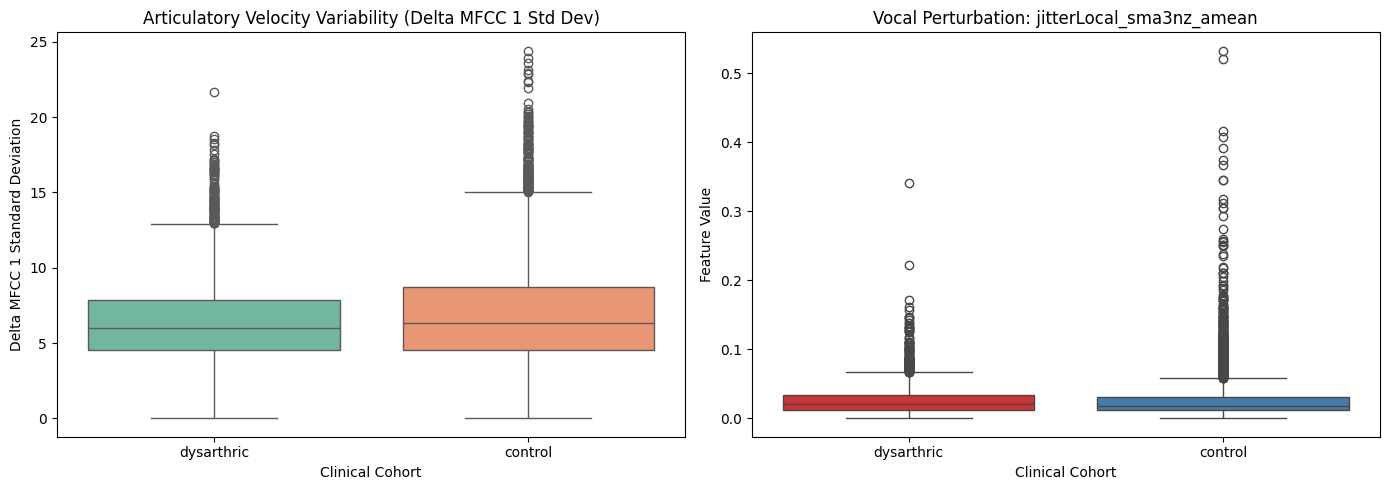

In [4]:
# Visualize key acoustic differences between Control and Dysarthric speech
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Articulation velocity variability (Delta MFCC standard deviation)
sns.boxplot(
    data=df_mfcc,
    x='label',
    y='delta_std_1',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title("Articulatory Velocity Variability (Delta MFCC 1 Std Dev)")
axes[0].set_xlabel("Clinical Cohort")
axes[0].set_ylabel("Delta MFCC 1 Standard Deviation")

# 2. Vocal instability / Shimmer from eGeMAPS
shimmer_cols = [c for c in df_egemaps.columns if 'shimmer' in c.lower() or 'jitter' in c.lower()]
target_col = shimmer_cols[0] if shimmer_cols else df_egemaps.columns[7]

sns.boxplot(
    data=df_egemaps,
    x='label',
    y=target_col,
    palette='Set1',
    ax=axes[1]
)
axes[1].set_title(f"Vocal Perturbation: {target_col}")
axes[1].set_xlabel("Clinical Cohort")
axes[1].set_ylabel("Feature Value")

plt.tight_layout()
plt.show()